# Week 10 Class Demo 2: KNN Classification and Model Selection with Healthcare Data

## Business Scenario
We keep the same `high_cost` business question from Demo 1 but change the modeling approach. K-Nearest Neighbors (KNN) asks whether a new record resembles historical records from class 0 or class 1.

## Learning Objectives
By the end of this class, students will be able to:
1. Explain KNN as a distance-and-voting algorithm.
2. Explain every major step in a KNN workflow and adapt it to another business dataset.
3. Explain why encoding and scaling affect the definition of “similar.”
4. Use training, validation, and test data for model selection.
5. Evaluate the effect of `k` and connect it to overfitting, underfitting, and bias-variance.
6. Compare KNN with logistic regression using technical and managerial criteria.
7. Build a reusable checklist for KNN classification in other business cases.

## Week 10 Learning Resources

- [Course Delivery Plan](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=42c15f8c0a8a487a9c578486-56)
- **Lecture 18:** [Recording](https://nait.video.yuja.com/V/Video?v=1347390&node=7565688&a=723165860) | [Notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture18_beginning_classification_part_2.ipynb)
- [Lecture 17–18 workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture17_18_Workbook.ipynb) | [Solution](https://colab.research.google.com/drive/1Wu6uNhSpgrU-ClN4um3nqw8IDCNldbdT?usp=sharing)
- [*Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/): Chapter 3, Chapter 5, and Chapter 6 through the NAIT O’Reilly subscription.


## How Demo 2 Connects to Demo 1

We deliberately keep the same target and predictors so that the **algorithm** becomes the main change. This is essential for a fair model comparison.

Logistic regression learns a global equation. KNN does not learn one global set of coefficients. Instead, KNN stores the training examples and asks: **Which training records are closest to this new record, and what classes do those neighbours have?**

The reusable workflow is:

**Define target → prepare predictors → split data → scale → choose candidate `k` values → validate → select `k` → refit → test → compare → recommend.**

## 1. Import the Libraries
The imports are largely the same as Demo 1. The important addition conceptually is `KNeighborsClassifier`. Reusing the same data preparation and metrics allows a more meaningful comparison.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, RocCurveDisplay
RANDOM_STATE=42
pd.set_option("display.max_columns",30)
print("Libraries loaded.")

Libraries loaded.


## 2. Load the Same Dataset
Using the same data keeps the modeling question consistent. When replicating KNN with another case, first load and inspect the new dataset exactly as you would for any model. KNN does not remove the need for data-quality checks.

In [13]:
DATA_FILE = "ClassDemo_health_data.csv"
df = pd.read_csv(DATA_FILE)
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
display(df.head())
print(df.dtypes)

Rows: 65,000; columns: 11


,patient_id,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol,health_cost
0,P000001,51,23.1,118,68,75,2.1,7.6,No,211,6288
1,P000002,31,19.5,88,75,78,6.9,6.6,No,141,4930
2,P000003,22,24.2,112,67,74,2.2,5.9,No,185,4877
3,P000004,23,31.1,88,57,82,4.1,7.7,No,144,5148
4,P000005,49,31.3,132,60,66,4.1,7.4,Yes,217,6505


patient_id         object
age                 int64
bmi               float64
systolic_bp         int64
diastolic_bp        int64
resting_hr          int64
exercise_hours    float64
sleep_hours       float64
smoker             object
cholesterol         int64
health_cost         int64
dtype: object


## 3. Recreate the Same Classification Target
The original `health_cost` is continuous, so we create the same median-based `high_cost` target as Demo 1. Keeping the target rule identical ensures that KNN and logistic regression attempt to solve the same business problem.

In [15]:
COST_THRESHOLD = df["health_cost"].median()
df["high_cost"] = (df["health_cost"] >= COST_THRESHOLD).astype(int)
print(f"Dataset median health cost: ${COST_THRESHOLD:,.0f}")
display(df["high_cost"].value_counts().rename(index={0:"Below median",1:"At/above median"}).to_frame("records"))
display(df["high_cost"].value_counts(normalize=True).rename("proportion").to_frame())

Dataset median health cost: $6,327


,records
high_cost,
At/above median,32522
Below median,32478


,proportion
high_cost,
1,0.500338
0,0.499662


### Why the Target Must Not Be Used as a Predictor
`health_cost` defines `high_cost`, so it is excluded from the predictors. The identifier is excluded as well. This leakage logic is algorithm-independent: changing from logistic regression to KNN does not make leakage acceptable.

In [17]:
model_df=df.drop(columns=["patient_id","health_cost"]).copy()
model_df["smoker"] = model_df["smoker"].map({"No":0,"Yes":1})
X=model_df.drop(columns="high_cost")
y=model_df["high_cost"]
print("Predictors:",list(X.columns))
display(X.head())

Predictors: ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'resting_hr', 'exercise_hours', 'sleep_hours', 'smoker', 'cholesterol']


,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol
0,51,23.1,118,68,75,2.1,7.6,0,211
1,31,19.5,88,75,78,6.9,6.6,0,141
2,22,24.2,112,67,74,2.2,5.9,0,185
3,23,31.1,88,57,82,4.1,7.7,0,144
4,49,31.3,132,60,66,4.1,7.4,1,217


### Student Check-in

If two models use different target definitions, can the scores be compared directly as if they solve the same problem?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

No. A different target definition changes the prediction task. For a useful algorithm comparison, keep the target and evaluation data consistent.

</details>

## 4. Understand KNN Step by Step

For one new observation, KNN performs the following logic:

1. Represent the new observation using the selected predictor values.
2. Calculate its distance to the training observations.
3. Sort the training observations by distance.
4. Keep the nearest `k` observations.
5. Count the class labels among those neighbours.
6. Predict the class receiving the majority vote.

A common distance measure is **Euclidean distance**:

$$
d(\mathbf{x}, \mathbf{z}) =
\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}
$$

### Business-Language Translation

Imagine a new customer, shipment, store, or machine. KNN asks:

> **Among historical cases that look most similar on the selected predictors, which outcome was most common?**

### Important Limitation

“Similar” means similar **according to the features and distance calculation we chose**. It does not mean the records are identical in every real-world sense.

### Student Check-in

If `k=7` and five of the seven nearest training records are class 1, what is the standard majority-vote prediction?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Class 1, because class 1 is the majority among the seven neighbours.

</details>

## 5. Why Scaling Is Essential for KNN

KNN calculates **distance**, and distance is affected by measurement units.

In this dataset, some variables can have much larger raw numerical ranges than a binary 0/1 variable. If we use the raw values, features with larger numerical scales can dominate the distance calculation simply because of their units.

`StandardScaler` standardizes each feature approximately as:

$$
z = \frac{x - \mu}{\sigma}
$$

where:

- $x$ = the original value
- $\mu$ = the mean of the feature
- $\sigma$ = the standard deviation of the feature
- $z$ = the standardized value

After standardization, each feature is expressed in terms of **how many standard deviations it is from its mean**.

This helps KNN calculate distances based on standardized differences rather than differences in the original measurement units.

### Transfer to Another Business Case

Suppose a retail model uses:

- `annual_spend` measured in thousands of dollars
- `website_visits` ranging from 0 to 20

Without scaling, `annual_spend` could have a much larger influence on the calculated distance simply because of its numerical scale.

Similarly, suppose a logistics model uses:

- distance travelled in kilometres
- package weight in kilograms
- a 0/1 priority flag

These features use very different measurement scales, so scaling deserves careful attention before applying KNN.

### Key Distinction from Logistic Regression

Scaling can be helpful for logistic regression because it may improve numerical optimization and make coefficient magnitudes easier to compare.

For **KNN, scaling is even more fundamental** because KNN is a distance-based algorithm.

> **Changing the scale can change which observations are considered the nearest neighbours, which can directly change the predicted class.**

In [22]:
numeric_ranges=X.max()-X.min()
display(numeric_ranges.sort_values(ascending=False).to_frame("raw_range"))

,raw_range
cholesterol,207.0
systolic_bp,80.0
age,62.0
resting_hr,62.0
diastolic_bp,51.0
bmi,29.5
exercise_hours,12.0
sleep_hours,6.5
smoker,1.0


### Student Check-in

Why can the identity of a record’s nearest neighbours change after standardization?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Because standardization changes the relative contribution of each feature to distance. Features with large raw units no longer dominate simply because of scale.

</details>

## 6. Create Training, Validation, and Test Sets

KNN introduces a modeling choice: **what value of `k` should we use?** If we choose `k` by checking the test set repeatedly, the test set becomes part of model tuning and no longer provides a clean final evaluation.

We therefore use three roles:
- **training:** fit candidate KNN models;
- **validation:** compare candidate `k` values;
- **test:** evaluate the selected approach after tuning.

The code first reserves 20% for test. Then it splits the remaining build data so that validation represents 25% of the build set.

### Replication rule
The exact percentages can vary, but keep the *roles* separate. For larger or more advanced projects, cross-validation is often used instead of one validation split.

In [25]:
X_build,X_test,y_build,y_test=
train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE,stratify=y)

X_train,X_val,y_train,y_val=
train_test_split(X_build,y_build,test_size=.25,random_state=RANDOM_STATE,stratify=y_build)
print("Training",X_train.shape,"Validation",X_val.shape,"Test",X_test.shape)

Training (39000, 9) Validation (13000, 9) Test (13000, 9)


### Read the Split Code Carefully
`X_build, X_test, y_build, y_test` preserves a final test set.

The second split works only inside the build portion, producing `X_train`/`y_train` and `X_val`/`y_val`.

`stratify` is used both times to preserve class proportions.

When adapting the code, keep `X` aligned with `y`. Never split predictors independently from their target labels.

## 7. Build a Baseline KNN Pipeline

The pipeline contains:
1. `StandardScaler()` to learn scaling parameters from training data;
2. `KNeighborsClassifier(n_neighbors=5)` to classify using five neighbours.

`fit(X_train, y_train)` stores the prepared training information needed for neighbours.

`predict(X_val)` generates classes for validation records.

The classification report then shows multiple metrics. At this stage, we are **not** claiming final test performance; validation is being used for model selection.

In [28]:
knn5=Pipeline([("scaler",StandardScaler()),("model",KNeighborsClassifier(n_neighbors=5))])
knn5.fit(X_train,y_train)
val_pred=knn5.predict(X_val)
print(classification_report(y_val,val_pred,digits=3))

              precision    recall  f1-score   support

           0      0.749     0.761     0.755      6496
           1      0.758     0.746     0.752      6504

    accuracy                          0.753     13000
   macro avg      0.753     0.753     0.753     13000
weighted avg      0.753     0.753     0.753     13000



### Student Check-in

Why fit the scaler inside the pipeline rather than standardizing the full dataset before splitting?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

The scaling parameters should be learned from training data, not from unseen validation or test observations. The pipeline helps preserve that separation.

</details>

## 8. What Does `k` Control?

`k` is the number of neighbours allowed to vote. It changes how local or smooth the model is.

### Small `k`
- decisions depend on very nearby records;
- the model can follow local patterns closely;
- noise and unusual observations can exert strong influence;
- this is associated with lower bias and higher variance.

### Large `k`
- the vote averages over a larger neighbourhood;
- predictions become smoother;
- small local patterns may disappear;
- this is associated with higher bias and lower variance.

### `k = 1` intuition
The single closest training record decides the outcome. That can be extremely flexible but unstable.

### Why try odd values?
For binary classification, odd values can reduce exact voting ties, although ties can still arise depending on implementation details and weighting.

### Student Check-in

If `k=1` performs extremely well on training cases but noticeably worse on validation cases, what does that suggest?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

It suggests overfitting or high variance. The model may be reacting too strongly to individual training examples rather than learning a pattern that generalizes.

</details>

## 9. Evaluate Several Values of `k`

The `for` loop repeats the same experiment for `k = 1, 3, 5, ... 31`. For each candidate:

1. create a fresh pipeline;
2. fit on training data;
3. predict validation classes;
4. calculate accuracy, precision, recall, and F1;
5. store one dictionary of results in the `rows` list.

`pd.DataFrame(rows)` converts the collected dictionaries into a comparison table. The plot then shows how model behaviour changes as `k` changes.

### Why this loop is highly reusable
In another case, `X_train`, `y_train`, `X_val`, and `y_val` can represent customers, shipments, transactions, or stores. The loop itself can remain nearly the same. What should change is the metric used to select the model if the business priorities differ.

,k,accuracy,precision,recall,f1
0,1,0.707,0.711,0.699,0.705
1,3,0.741,0.745,0.734,0.740
2,5,0.753,0.758,0.746,0.752
3,7,0.764,0.769,0.755,0.762
4,9,0.766,0.771,0.758,0.764
5,11,0.769,0.773,0.762,0.768
6,13,0.774,0.778,0.766,0.772
7,15,0.772,0.777,0.763,0.770
8,17,0.771,0.775,0.764,0.769
9,19,0.773,0.779,0.764,0.771


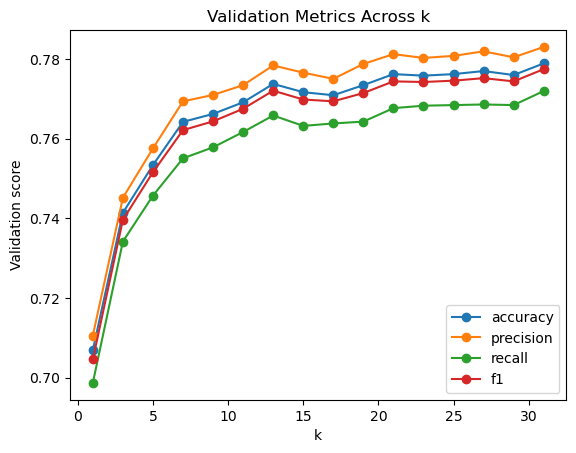

In [33]:
rows=[]
for k in range(1,32,2):
    m=Pipeline([("scaler",StandardScaler()),("model",KNeighborsClassifier(n_neighbors=k))])
    m.fit(X_train,y_train); p=m.predict(X_val)
    rows.append({"k":k,"accuracy":accuracy_score(y_val,p),"precision":precision_score(y_val,p),"recall":recall_score(y_val,p),"f1":f1_score(y_val,p)})
k_results=pd.DataFrame(rows)
display(k_results.round(3))
for col in ["accuracy","precision","recall","f1"]: plt.plot(k_results.k,k_results[col],marker="o",label=col)
plt.xlabel("k"); plt.ylabel("Validation score"); plt.title("Validation Metrics Across k"); plt.legend(); plt.show()

### Student Check-in

Why should we not simply choose the `k` with the highest accuracy in every business case?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Because different businesses assign different importance to false positives and false negatives. The selection metric should reflect the decision objective, not habit.

</details>

## 10. Select `k`, Refit, and Test

For this demonstration, we select the `k` with the highest **validation F1**. This is an explicit modeling rule.

`idxmax()` finds the row index containing the largest validation F1. The code then retrieves that row's `k`.

After selecting `k`, we refit KNN using `X_build` and `y_build`. This combines the earlier training and validation information because tuning is complete.

Only then do we predict on `X_test`. This preserves the test set for the final evaluation.

### Generalize the selection rule
If missing positives is especially costly, choose based on validation recall or a cost function. If review capacity is very constrained, precision may become more important. Document the rule before reporting final test results.

In [36]:
def metric_table(y_true,pred,prob):
    return pd.Series({"accuracy":accuracy_score(y_true,pred),"precision":precision_score(y_true,pred,zero_division=0),"recall":recall_score(y_true,pred,zero_division=0),"f1":f1_score(y_true,pred,zero_division=0),"roc_auc":roc_auc_score(y_true,prob)}).round(3).to_frame("score")

Selected k: 31


,score
accuracy,0.783
precision,0.784
recall,0.780
f1,0.782
roc_auc,0.865


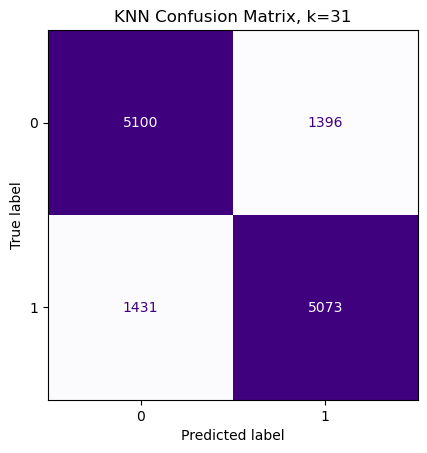

In [37]:
best_k=int(k_results.loc[k_results.f1.idxmax(),"k"])
final_knn=
Pipeline([("scaler",StandardScaler()),("model",KNeighborsClassifier(n_neighbors=best_k))])
final_knn.fit(X_build,y_build)
knn_prob=final_knn.predict_proba(X_test)[:,1]
knn_pred=(knn_prob>=.50).astype(int)
print("Selected k:",best_k)
display(metric_table(y_test,knn_pred,knn_prob))
ConfusionMatrixDisplay.from_predictions(y_test,knn_pred,cmap="Purples",colorbar=False); plt.title(f"KNN Confusion Matrix, k={best_k}"); plt.show()

### Student Check-in

Why do we refit on `X_build` after selecting `k` instead of keeping only the smaller training partition?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Once the hyperparameter is selected, the validation set is no longer needed for tuning. Reusing the full build portion gives the final model more labeled examples while the test set remains untouched.

</details>

## 11. Inspect the Neighbours Behind One Prediction

The next code block illustrates a local explanation.

`X_test.iloc[[0]]` selects one test record while keeping it in table form.

The pipeline's fitted scaler transforms the record using the same scaling learned during model fitting.

`.kneighbors()` returns the distances and row positions of nearby build records.

We then display those records together with distance and known target class.

### What students should learn
A KNN prediction can be explained locally by showing which historical examples influenced the vote. But this does **not** provide a global statement such as “a one-unit increase in X changes the odds by Y.” That kind of global coefficient interpretation belongs more naturally to logistic regression.

In [40]:
case=X_test.iloc[[0]]
case_scaled=final_knn.named_steps["scaler"].transform(case)
dist,idx=final_knn.named_steps["model"].kneighbors(case_scaled)
neighbours=X_build.iloc[idx[0]].copy()
neighbours["distance"]=dist[0]
neighbours["high_cost"]=y_build.iloc[idx[0]].values
print("New record"); display(case)
print("Nearest records"); display(neighbours.round(3))

New record


,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol
47547,30,30.1,97,52,69,4.5,6.6,0,147


Nearest records


,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol,distance,high_cost
62750,28,27.9,96,53,72,3.5,6.1,0,143,0.912,0
35059,25,28.7,102,52,69,5.6,7.0,0,135,0.925,0
16361,19,30.4,100,53,65,5.2,6.2,0,150,0.980,0
37986,25,28.0,99,54,66,4.9,6.6,0,124,1.008,0
40578,20,30.3,102,52,65,4.8,6.7,0,167,1.058,0
14304,18,32.2,97,54,74,4.9,6.7,0,154,1.077,0
17268,30,25.8,99,53,68,4.4,7.2,0,138,1.079,0
21757,40,28.8,93,55,72,3.3,6.8,0,136,1.107,0
54807,24,31.0,93,57,66,5.3,7.1,0,157,1.113,0
6268,27,26.3,93,57,66,4.4,6.5,0,153,1.120,0


### Student Check-in

If a neighbouring record has a short model distance, what exactly can we conclude?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Only that it is close under the selected predictors, encoding, scaling, and distance calculation. We cannot conclude that the records are identical in every meaningful real-world respect.

</details>

## 12. Compare KNN with Logistic Regression Fairly

The comparison fits logistic regression on the same `X_build`/`y_build` and evaluates on the same `X_test`/`y_test`. This controls the evaluation conditions.

### Why compare more than one metric?
A model can have similar accuracy but meaningfully different precision or recall. ROC AUC compares ranking ability using probabilities. F1 summarizes precision-recall balance.

### Why business criteria still matter
Even if one score is slightly higher, a final choice may also consider:
- ease of explanation;
- prediction workload;
- stability;
- governance and monitoring;
- the kind of explanation decision makers require.

KNN provides intuitive local neighbour examples. Logistic regression provides global coefficient and odds-ratio summaries.

In [43]:
log_model=Pipeline([("scaler",StandardScaler()),("model",LogisticRegression(max_iter=1000,random_state=RANDOM_STATE))])
log_model.fit(X_build,y_build)
log_prob=log_model.predict_proba(X_test)[:,1]; log_pred=(log_prob>=.5).astype(int)
def row(name,pred,prob): return {"model":name,"accuracy":accuracy_score(y_test,pred),"precision":precision_score(y_test,pred),"recall":recall_score(y_test,pred),"f1":f1_score(y_test,pred),"roc_auc":roc_auc_score(y_test,prob)}
comparison=pd.DataFrame([row("Logistic regression",log_pred,log_prob),row(f"KNN, k={best_k}",knn_pred,knn_prob)]).set_index("model")
display(comparison.round(3))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic regression,0.792,0.795,0.788,0.792,0.878
"KNN, k=31",0.783,0.784,0.780,0.782,0.865


### Student Check-in

If two models have nearly identical metrics but managers need a concise global explanation of predictor direction, which model may be easier to communicate?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Logistic regression may be easier because coefficients and odds ratios provide a global directional summary. The answer is a communication and governance trade-off, not simply a score comparison.

</details>

## 13. Replicate KNN in Another Business Case

Use this checklist:

### A. Define class 1 clearly
Examples: churn, late delivery, repeat purchase, equipment failure, or a legitimate fraud-review flag.

### B. Select predictors available before the decision
Remove IDs and leakage fields. Encode categorical variables.

### C. Ask whether “distance” is meaningful
KNN assumes the selected feature space represents useful similarity. Irrelevant features can make neighbours less meaningful.

### D. Scale numeric features
Place scaling inside a pipeline.

### E. Reserve data for model selection and testing
Choose `k` using validation or cross-validation rather than repeatedly examining test results.

### F. Select a metric based on business error costs
Do not automatically optimize accuracy or F1.

### G. Inspect generalization and operational practicality
Compare with a baseline model and explain why the chosen approach fits the decision.

## 14. Worked Transfer Example: Late Delivery

Imagine a logistics company wants to predict `late_delivery = 1`. Possible predictors measured before dispatch could include planned distance, shipment weight, shipping service, warehouse workload, and scheduled transit time.

To adapt this KNN code:
1. replace the healthcare CSV with the logistics CSV;
2. set `y = df["late_delivery"]`;
3. build `X` from pre-dispatch features;
4. encode categories such as service type;
5. keep `StandardScaler` for numeric distance-based features;
6. use the same train/validation/test logic;
7. evaluate several `k` values;
8. decide whether recall, precision, F1, or a cost-based measure best represents the logistics objective.

The algorithmic skeleton barely changes. The difficult work is redefining the business meaning correctly.

### Student Check-in

For the late-delivery case, give one possible leakage feature.

<details>
<summary><strong>Reveal suggested answer</strong></summary>

`actual_delivery_time` would be leakage for a model intended to predict lateness before dispatch because the actual delivery time is only known after the outcome occurs.

</details>

## 15. Student Transfer Challenge
Choose a different business case and write down:
1. the binary target;
2. five candidate predictors;
3. which features require encoding;
4. why scaling matters;
5. one leakage feature to exclude;
6. what small and large `k` would mean;
7. the validation metric you would use and why;
8. what managerial factor might lead you to choose logistic regression instead of KNN.

### Student Check-in

What is the central lesson for replicating KNN?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Keep the workflow, but redefine the target, predictors, preprocessing, error costs, and similarity concept for the new business problem. Do not copy column names or evaluation priorities without business justification.

</details>

## Key Takeaways
- KNN predicts from nearby historical examples rather than one global equation.
- Scaling is fundamental because KNN depends on distance.
- `k` controls locality and the bias-variance trade-off.
- Hyperparameters should be chosen using validation evidence, not the final test set.
- Replicating KNN is not just changing a filename. You must redefine what similarity, class 1, errors, and success mean in the new business context.
- Comparing models requires the same target, evaluation data, and clearly stated business criteria.